# Práctica 6 · Mi primer modelo de IA en mi computadora
IN1050 · Herramientas de Procesamiento para IA · Parcial II

En el Parcial I corrieron modelos en Colab, en una computadora de Google. Hoy el modelo corre **en esta computadora**, dentro del entorno virtual `.venv` que crearon con `python -m venv .venv`.

**Antes de correr:** arriba a la derecha, en *Select Kernel*, elijan **Python Environments → .venv**. Después, *Run All*.

In [1]:
# 1. ¿Dónde estoy corriendo? La ruta del intérprete debe terminar en .venv\Scripts\python.exe
import sys, platform
print("Python:", sys.version.split()[0])
print("Intérprete:", sys.executable)
print("Sistema:", platform.system(), platform.release())

Python: 3.14.10
Intérprete: c:\Users\jessi\portafolio-herramientas-ia\practica-6\.venv\Scripts\python.exe
Sistema: Windows 11


In [2]:
# 2. Versiones de las bibliotecas (deben coincidir con requirements.txt)
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # aviso de las barras de progreso
warnings.filterwarnings("ignore", category=FutureWarning)            # avisos de cambios en versiones futuras
import torch, transformers
from importlib.metadata import version
for paquete in ["torch", "transformers"]:
    print(f"{paquete:14} {version(paquete)}")
print("Hilos de CPU que usa torch:", torch.get_num_threads())

torch          2.15.0
transformers   5.23.0
Hilos de CPU que usa torch: 10


## El modelo
| Dato | Valor |
|---|---|
| Identificador | [google/mobilenet_v2_1.0_224](https://huggingface.co/google/mobilenet_v2_1.0_224) |
| Tarea | `image-classification`: dice qué hay en una foto |
| Parámetros | 3.5 millones (≈ 14 MB): cabe en cualquier computadora |
| Entrenado con | ImageNet: 1,000 categorías, con nombres en inglés |
| Licencia | other (ver la Model Card) |

La primera vez, el modelo se descarga de Hugging Face y se guarda en la caché (`C:\Users\<tú>\.cache\huggingface`). Las siguientes veces se carga de ahí.

In [11]:
# 3. Cargar el modelo (la primera vez lo descarga)
import time
from transformers import pipeline
inicio = time.perf_counter()
clasificador = pipeline("image-classification", model="google/mobilenet_v2_1.0_224")
print(f"Modelo listo en {time.perf_counter() - inicio:.1f} s")

Loading weights: 100%|██████████| 314/314 [00:00<00:00, 4455.32it/s]

Modelo listo en 0.4 s


In [4]:
# 4. La función que usa el modelo: recibe la ruta de una imagen y regresa las 3 categorías más probables
def procesar(ruta_imagen):
    inicio = time.perf_counter()
    resultado = clasificador(ruta_imagen, top_k=3)
    segundos = time.perf_counter() - inicio
    return [(r["label"], round(r["score"] * 100, 1)) for r in resultado], segundos

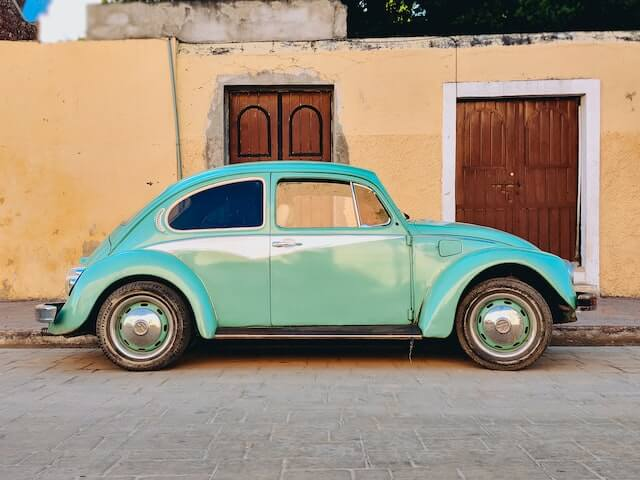

In [5]:
# 5. Una imagen de ejemplo: el modelo también acepta la dirección de una imagen en internet
from pathlib import Path
from IPython.display import Image, display
EJEMPLO = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/car.jpg"
display(Image(url=EJEMPLO, embed=True, width=320))   # embed: la imagen queda guardada en el cuaderno

In [6]:
# 6. ¿Qué ve el modelo?
categorias, segundos = procesar(EJEMPLO)
for nombre, porcentaje in categorias:
    print(f"{porcentaje:5.1f} %  {nombre}")
print(f"Tiempo: {segundos:.2f} s (incluye bajar la imagen de internet)")

 24.6 %  beach wagon, station wagon, wagon, estate car, beach waggon, station waggon, waggon
 12.5 %  sports car, sport car
 10.0 %  pickup, pickup truck
Tiempo: 0.70 s (incluye bajar la imagen de internet)


## Tu turno
1. Copia una foto tuya (JPG) a esta carpeta, junto a este cuaderno, con el nombre `mi-foto.jpg`.
2. Corre la celda de abajo. Si quieres probar otra, cambia el nombre del archivo.

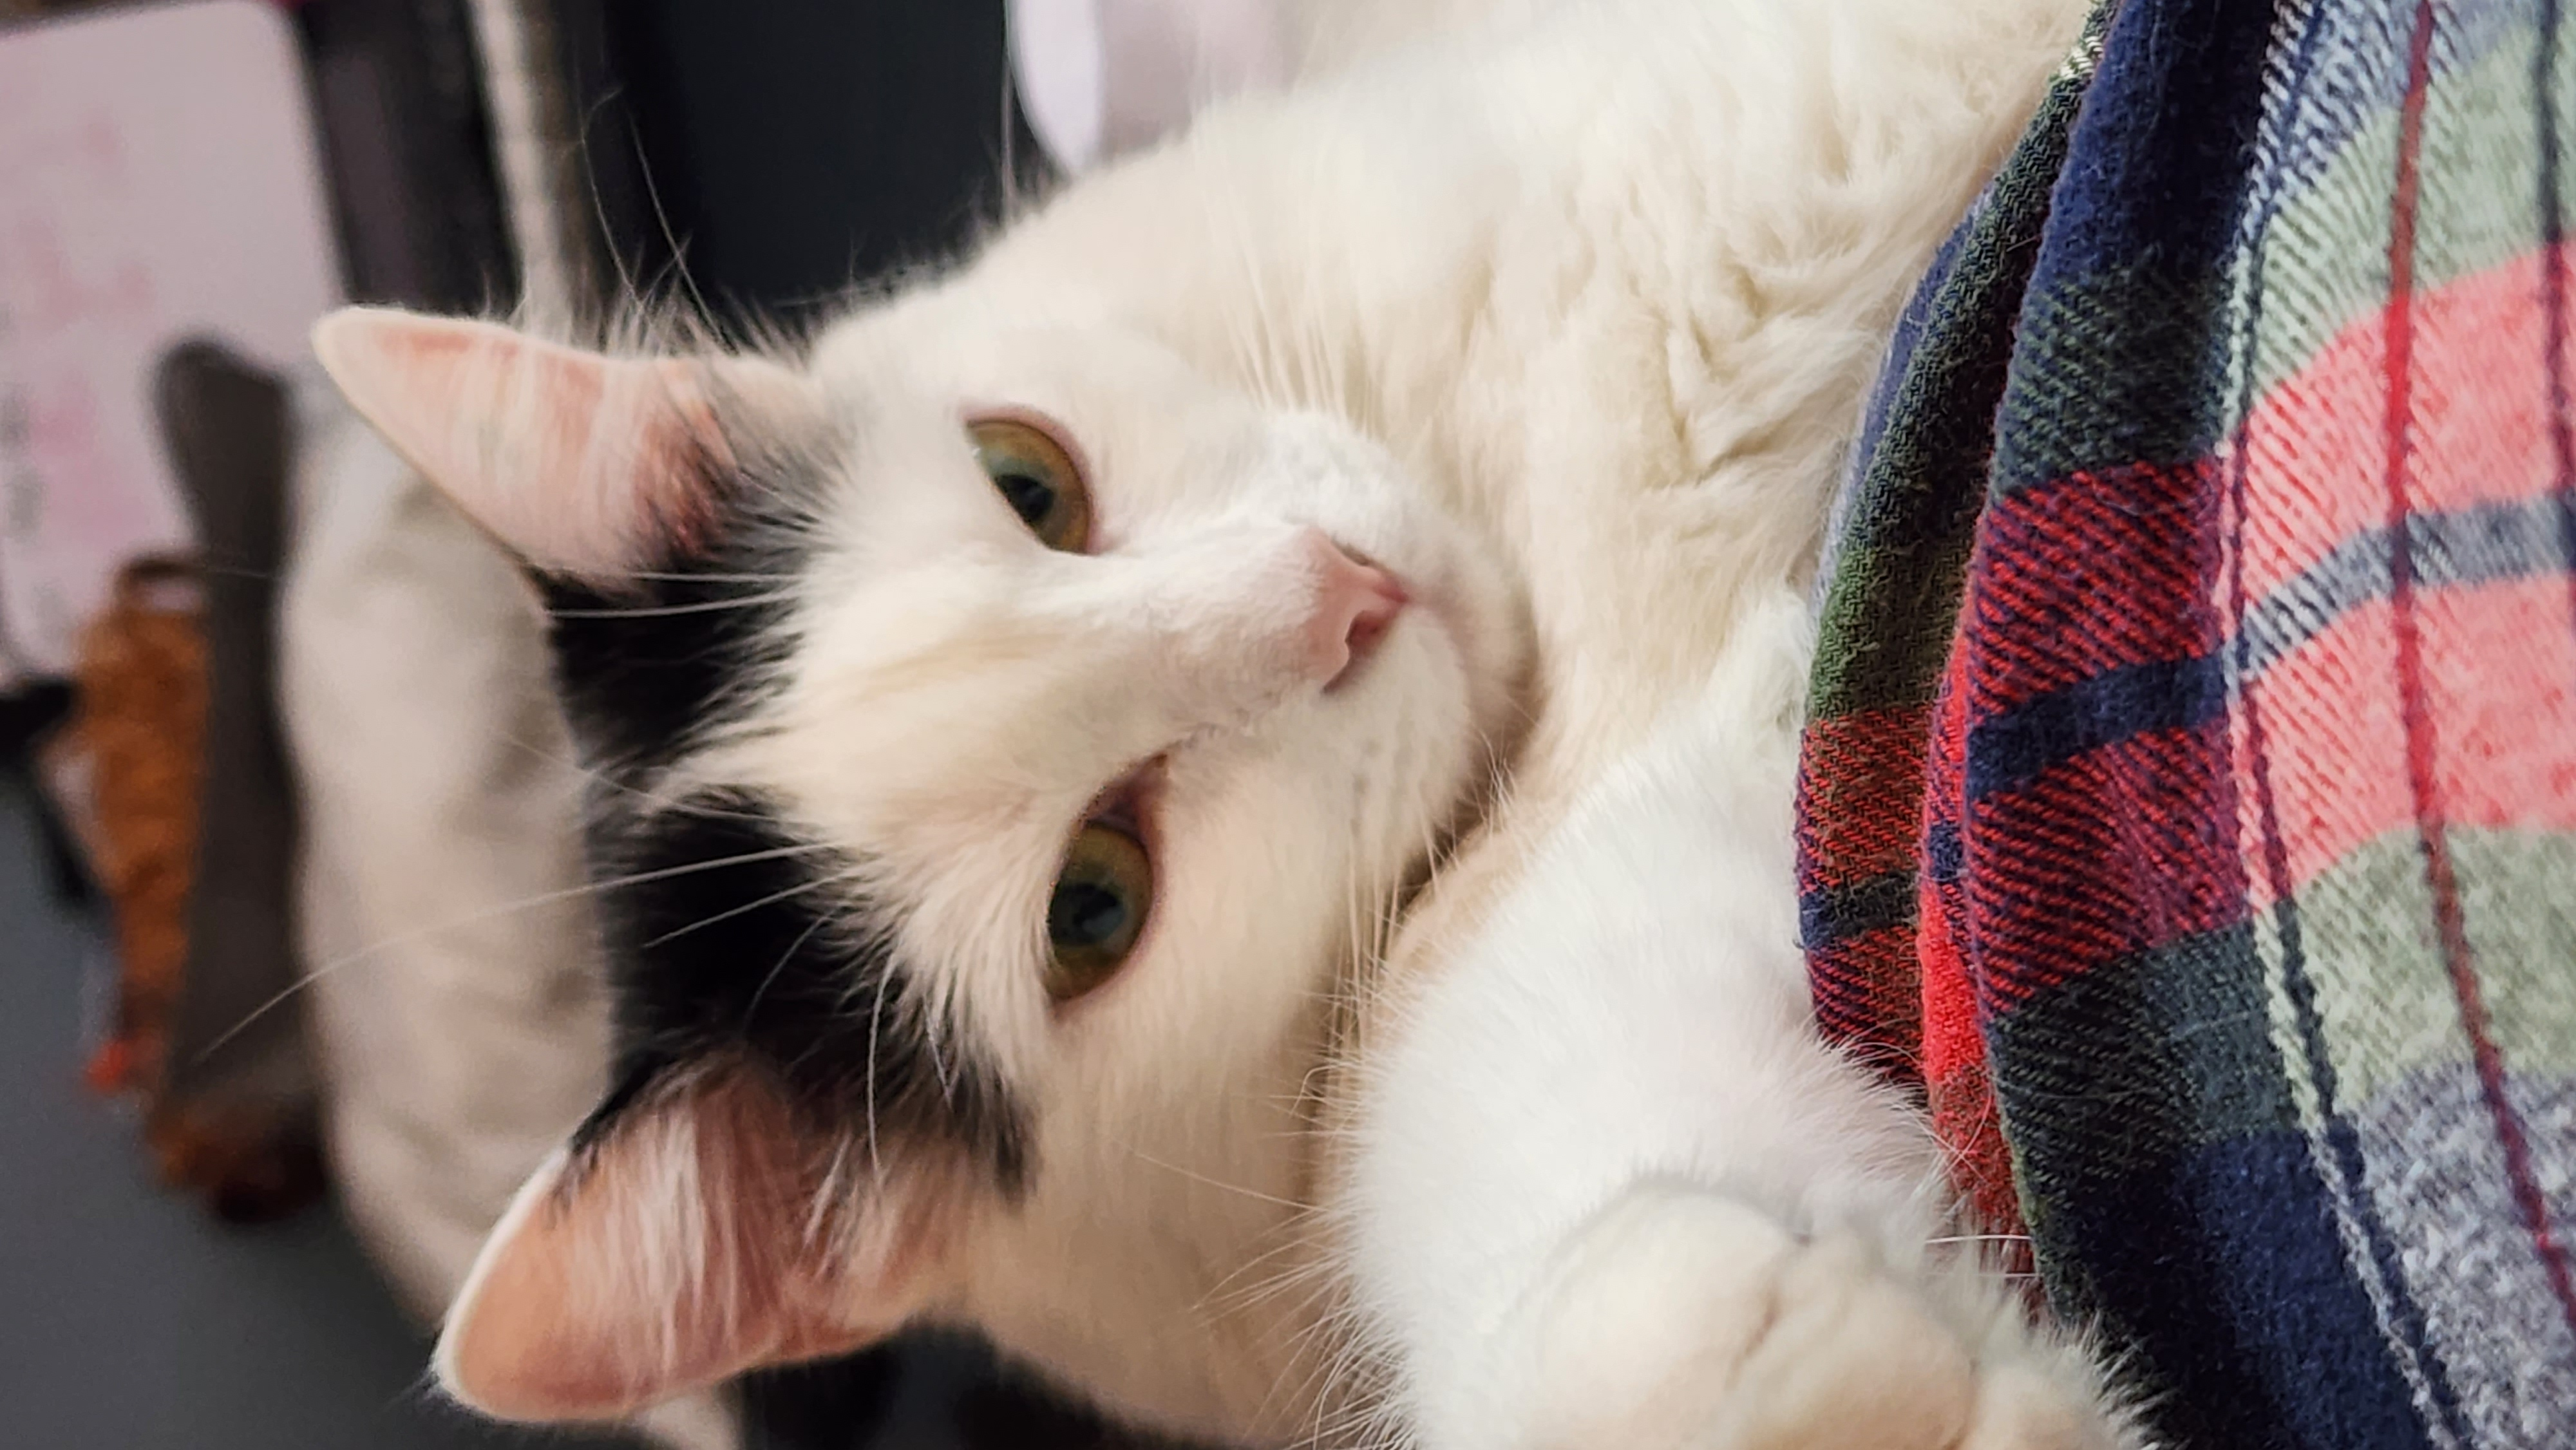

 56.2 %  lynx, catamount
  7.8 %  Siamese cat, Siamese
  6.1 %  Egyptian cat
Tiempo en CPU: 1.31 s


In [9]:
# 7. Tu foto
mi_foto = Path("mi-foto.jpg")
if mi_foto.exists():
    display(Image(filename=mi_foto, width=320))
    categorias, segundos = procesar(str(mi_foto))
    for nombre, porcentaje in categorias:
        print(f"{porcentaje:5.1f} %  {nombre}")
    print(f"Tiempo en CPU: {segundos:.2f} s")
else:
    print("Todavía no hay mi-foto.jpg en esta carpeta.")

## Preguntas
1. ¿Qué ruta imprimió la celda 1? ¿Cómo sabes que es el entorno virtual y no el Python de la computadora?
    Imprimió:  c:\Users\jessi\portafolio-herramientas-ia\practica-6\.venv\Scripts\python.exe
    Porque pasa por .venv que se refiere al entorno virtual.
2. ¿Cuánto tardó en cargar el modelo la primera vez y cuánto si vuelves a correr la celda 3? ¿Por qué?
    Más de 5 segundos, al volverlo a cargar tarda menos del segundo. Al incio tardo más porque tuvo que descargarlo.
3. ¿Acertó con tu foto? ¿Por qué crees que las categorías están en inglés?
    Acertó en que se trataba de un felino, pero no en que especie.
    Porque fue entrenado con datos en inglés.


Responde aquí, en esta celda (doble clic para editarla).